# Berkshire Prosecution Analysis

    **Study period:** 2017–2024 case cohorts. **Review date:** November 23, 2026.

    Adapted from the team's `parin-dev` county analysis template and shared chart palette.
    One case unit is an observed docket number × defendant ID; unresolved identities are excluded and counted.
    Open cases are included in volume, excluded from outcome analysis. The most severe observed charge outcome wins:
    Trial Conviction > Plea > CWOF > Diversion > Acquittal > Dismissal > Other > Unknown.

    **Read the coverage section first.** Fields above 20% missing are insufficient under the shared rule;
    dependent metrics are withheld. Explicit Unknown and blank Missing remain separate. Disparity groups below 30
    are suppressed. This notebook reports recorded evidence, not causal effects, actual time served, or statewide history.

    **County-specific date limitation:** Initiated Dt is an initiation date; its equivalence to court filing needs client confirmation.

**Figure location:** `figures/berkshire/` at the repository root. Tables remain beside this notebook.


## Setup
Run all cells in order. Set the `PROSECUTOR_DATA_ROOT` environment variable if the original spreadsheets are elsewhere. Raw files are read only.


In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for base in (Path.cwd(), *Path.cwd().parents)
             for p in (base, base / 'fa26')
             if (p / 'county_adapter.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from its county folder or the review package root.')
REPO_ROOT=ROOT.parent
sys.path.insert(0, str(REPO_ROOT))
sys.path.insert(0, str(ROOT))
from viz_style import set_style, OUTCOME_COLORS, BAIL_COLORS, stacked_pct_bar
from county_charts import bail_table, MIN_CELL
import county_adapter as adapter
import county_review_charts as charts
set_style()

SLUG='berkshire'; COUNTY='Berkshire'; BERK=SLUG=='berkshire'
COUNTY_DIR=ROOT/SLUG
FIG_DIR=REPO_ROOT/'figures'/SLUG; TABLE_DIR=COUNTY_DIR/'tables'
FIG_DIR.mkdir(parents=True,exist_ok=True); TABLE_DIR.mkdir(exist_ok=True)
DATA_ROOT=Path(os.environ.get('PROSECUTOR_DATA_ROOT', str(ROOT.parent)))
YEARS=range(2017,2025)
YEAR_LABEL='Recorded initiation year (filing proxy)' if BERK else 'Unverified case-ID prefix year'
tables={}; statuses=[]
def save_table(name,frame):
    tables[name]=frame
    frame.to_csv(TABLE_DIR/(name+'.csv'),index=True)
    display(frame)
    return frame
def status(question,state,reason):
    statuses.append(dict(question=question,status=state,reason=reason))
    display(Markdown('**'+state+'.** '+reason))
def fig(name):return FIG_DIR/(SLUG+'_'+name+'.png')


## Load Data and Map Dispositions
Both Berkshire continuation sheets are read, including the first data row on List_Frame_2. Cape duplicate headers are disambiguated before selecting fields. Identical export copies and shifted/unattached Cape rows are flagged before aggregation.


In [2]:
raw=adapter.load_sources(SLUG, DATA_ROOT)
filed,disposed,bail,inventory,source_hashes,exclusions,crosswalk=adapter.prepare(SLUG,raw)
save_table('source_inventory',inventory)
save_table('source_exclusions',exclusions)
save_table('source_sha256',pd.Series(source_hashes,name='sha256').to_frame())
save_table('disposition_crosswalk',crosswalk)


,extract,sheet,rows,source_columns,repeated_export_rows
0,filed,List_Frame_1,65535,14,24
1,filed,List_Frame_2,11715,14,1
2,disposed,List_Frame_1,65535,37,2
3,disposed,List_Frame_2,7361,37,16
4,bail,List_Frame_1,25420,11,2


,extract,source_rows,removed_rows,retained_rows,duplicate_export_rows,shifted_rows,unattached_rows
0,filed,77250,25,77225,25,0,0
1,disposed,72896,18,72878,18,0,0


,sha256
filed,d546bd85a620df30a60edfddf769ea51e227b032b9646f...
disposed,928f932b84ba90a6be508b6075b7ede98892dc117c491d...
bail,8d8e2c666d4b49cfe0e17af415df6574ef9cd55a8572e9...


,raw_disposition,outcome,charge_rows
0,Accord and Satisfaction,Other,10
1,Conflict / Transfer,Other,11
2,Continued Without Change of Plea,Other,1079
3,Continued Without Finding,CWOF,156
4,Continued Without Finding,Other,36
5,Converted to Civil,Other,353
6,Directed Verdict,Acquittal,26
7,Dismissed,Dismissal,21407
8,Dismissed - Show Cause,Dismissal,37
9,Dismissed Without Prejudice COVID19,Dismissal,430


,raw_disposition,outcome,charge_rows
0,Accord and Satisfaction,Other,10
1,Conflict / Transfer,Other,11
2,Continued Without Change of Plea,Other,1079
3,Continued Without Finding,CWOF,156
4,Continued Without Finding,Other,36
5,Converted to Civil,Other,353
6,Directed Verdict,Acquittal,26
7,Dismissed,Dismissal,21407
8,Dismissed - Show Cause,Dismissal,37
9,Dismissed Without Prejudice COVID19,Dismissal,430


**Mapping decisions.** Nolle prosequi is included in Dismissal for the shared comparison. CWOF remains separate.
    Berkshire uses disposition type, description and sentence translation together: a generic guilty record is Other if its plea/trial route is unknown.
    A plea route alone does not establish conviction or incarceration. Conflicting CWOF/custody evidence is Other pending review.
    Cape GPL is Plea, GJT/GBT/GJW are Trial Conviction, CWF is CWOF, and NOP/NPDPH/DIS/OBJ are Dismissal.
    Pretrial probation is not automatically treated as verified diversion. See the complete exported crosswalk rather than inferring meanings from colors.


## 0. Data Coverage
    Coverage is calculated on retained criminal charge rows in the target cohort **before excluding missing case identities**.
    The template's 20% threshold is then checked again on the case denominator used by each metric.
    A missing substantive offense-category crosswalk does not prevent a clearly labeled supplementary comparison by source offense class.
    A field can pass the completeness threshold while still needing semantic validation.


In [3]:
coverage=adapter.coverage_table(filed,disposed)
save_table('coverage_charge_fields',coverage)
INSUFFICIENT=set(coverage.loc[(coverage.extract=='disposed') & coverage.status.eq('insufficient data'),'field'])
print('Insufficient disposed-extract fields:', ', '.join(sorted(INSUFFICIENT)) or 'none')


,extract,field,rows,missing_rows,pct_missing,years_available,status,note
0,filed,docket,57989,171,0.294884,2017-2024,ok,
1,filed,defendant_id,57989,0,0.000000,2017-2024,ok,
2,filed,filing_date,57989,0,0.000000,2017-2024,ok,
3,filed,charge_level,57989,0,0.000000,2017-2024,ok,
4,filed,offense_category,57989,57989,100.000000,none,insufficient data,No validated substantive offense crosswalk; so...
5,filed,court,57989,0,0.000000,2017-2024,ok,
6,filed,race,57989,1269,2.188346,2017-2024,ok,
7,filed,sex,57989,135,0.232803,2017-2024,ok,
8,disposed,docket,52959,157,0.296456,2017-2024,ok,
9,disposed,defendant_id,52959,0,0.000000,2017-2024,ok,


Insufficient disposed-extract fields: offense_category, sentence_type


## Build Case Table
    The primary key is docket × defendant, not source row or internal case ID. Berkshire selects the docket associated with the recorded district/superior court, or the sole available docket. Ambiguous dual-docket rows remain unresolved; court-stage histories cannot be reconstructed.
    Case dates use earliest recorded initiation and latest observed disposition. Class ranks F > M+ > M−; the charge ordinal breaks ties when available, then charge code and source row. Cape has no charge ordinal, so the tie-break is deterministic rather than a verified lead charge.
    A case with any charge recorded as open or unconfirmed is Pending and excluded from outcomes. Closed cases with missing outcomes retain Unknown.
    Cohorts use earliest initiation year in Berkshire; Cape's supplementary cohorts use the unverified ID-prefix year. These differ from the older notebooks' disposition-year cohorts.


In [4]:
filed_cases,all_cases,cases=adapter.build_cases(filed,disposed)
metric_coverage=adapter.metric_coverage(cases)
save_table('coverage_case_metrics',metric_coverage)
cohort=pd.DataFrame([dict(filed_case_units=len(filed_cases),observed_case_units=len(all_cases),
    pending_or_unconfirmed_excluded=int(all_cases.outcome.eq('Pending').sum()),disposed_case_units=len(cases))])
save_table('cohort_flow',cohort)
identity=pd.DataFrame([dict(extract=label,unresolved_docket_or_defendant_rows=int(df.case_key.isna().sum()),
    source_case_ids=df.case_id.nunique(),resolved_docket_defendant_units=df.case_key.nunique())
    for label,df in [('filed',filed),('disposed',disposed)]])
save_table('case_identity_audit',identity)
def allowed(field):
    raw_field='sentence_type' if field=='sentence' else field
    return raw_field not in INSUFFICIENT and metric_coverage.at[field,'status']=='ok'
filed_identity_ok=not coverage.loc[(coverage.extract=='filed') & coverage.field.isin(['docket','defendant_id']),'status'].eq('insufficient data').any()
disposed_identity_ok=not coverage.loc[(coverage.extract=='disposed') & coverage.field.isin(['docket','defendant_id']),'status'].eq('insufficient data').any()


,denominator,missing_or_conflicting,pct_missing,status
field,,,,
race,29788,635,2.131731,ok
sex,29788,69,0.231637,ok
court,29788,0,0.000000,ok
sentence,6008,70,1.165113,ok


,filed_case_units,observed_case_units,pending_or_unconfirmed_excluded,disposed_case_units
0,32262,29965,177,29788


,extract,unresolved_docket_or_defendant_rows,source_case_ids,resolved_docket_defendant_units
0,filed,176,36212,36165
1,disposed,162,34439,34404


## 1. Volume and Trend
    **Question:** How many cases were filed each year, and how has that changed since 2017?
    **Metric:** criminal case units per year, percentage change year over year and versus 2017.
    **Method:** use the filed extract, including open cases, and count each resolved docket/defendant unit once. Cape cannot provide a confirmed filing-year count.


**Partially answerable.** Recorded initiation is a filing proxy.

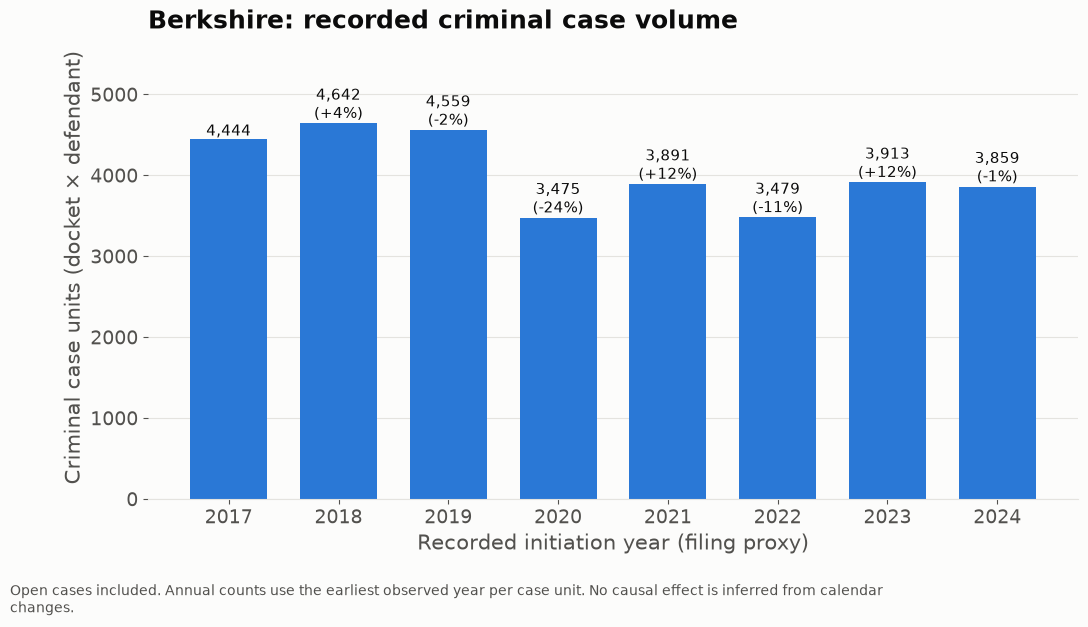

,cases,pct_change_yoy,pct_change_vs_2017
year,,,
2017,4444,NaN,0.0
2018,4642,4.5,4.5
2019,4559,-1.8,2.6
2020,3475,-23.8,-21.8
2021,3891,12.0,-12.4
2022,3479,-10.6,-21.7
2023,3913,12.5,-11.9
2024,3859,-1.4,-13.2


2017: 4,444; 2024: 3,859; change: -13.2%


In [5]:
vol=filed_cases.groupby('year').size().reindex(YEARS,fill_value=0)
vol.index=vol.index.astype(int)
if filed_identity_ok:
    status('Q1','Partially answerable', 'Recorded initiation is a filing proxy.' if BERK else 'No filing date; the following is an unverified case-ID-year proxy, not confirmed filings.')
    save_table('q1_volume',charts.volume(vol,COUNTY,YEAR_LABEL,fig('q1_volume')))
    print(f'2017: {vol.loc[2017]:,}; 2024: {vol.loc[2024]:,}; change: {(vol.loc[2024]/vol.loc[2017]-1):.1%}')
else:
    status('Q1','Unavailable under shared rule','Docket/defendant coverage fails the 20% missing-data threshold.')
    charts.unavailable(COUNTY+': Q1',statuses[-1]['reason'],fig('q1_volume'))


## 2. Per-Capita Rate
    **Question:** How many cases are filed per 10,000 residents?
    **Method:** Q1 recorded case units / annual July 1 Census PEP population × 10,000.
    The existing population estimates are reused; no new population values are retrieved. Vintages change at 2020. Cape combines Barnstable, Dukes and Nantucket. This is a caseload-to-population proxy, not a resident victimization rate.


**Partially answerable.** The numerator inherits Q1’s initiation/ID-year limitation; population is annual and sourced.

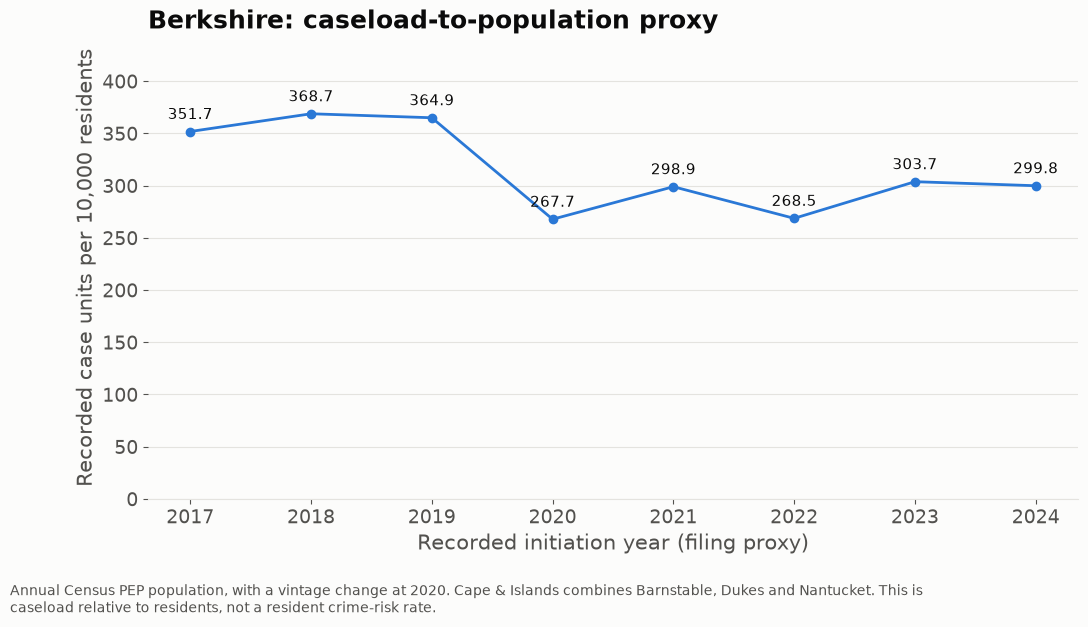

,recorded_case_units_per_10k
year,
2017,351.713058
2018,368.702393
2019,364.883468
2020,267.694820
2021,298.850222
2022,268.542890
2023,303.655821
2024,299.784037


In [6]:
population=pd.read_csv(ROOT/'annual_population.csv').set_index('year')
pop=population['berkshire' if BERK else 'cape_and_islands']
assert pop.reindex(YEARS).gt(0).all()
if filed_identity_ok:
    status('Q2','Partially answerable','The numerator inherits Q1’s initiation/ID-year limitation; population is annual and sourced.')
    save_table('q2_per_capita',charts.per_capita(vol,pop,COUNTY,YEAR_LABEL,fig('q2_per_capita')))
else:
    status('Q2','Unavailable under shared rule','Q1 does not meet the case-identity coverage rule.')
    charts.unavailable(COUNTY+': Q2',statuses[-1]['reason'],fig('q2_per_capita'))


## 3. Case Outcomes
    **Question:** Of charged cases, what share end in dismissal, diversion, plea, trial conviction, or acquittal?
    **Denominator:** observed disposed criminal docket/defendant units in the 2017–2024 cohort, not all filed cases.
    The shared severity hierarchy applies across all observed charges. Open cases are excluded. Recent cohorts disproportionately contain fast-resolving cases; this is not an eventual-outcome forecast. Cape cohorts remain proxies. Unknown is kept visible.


**Partially answerable.** Observed disposed-case shares are available. Filing semantics, unresolved cases and unverified diversion limit a complete answer.

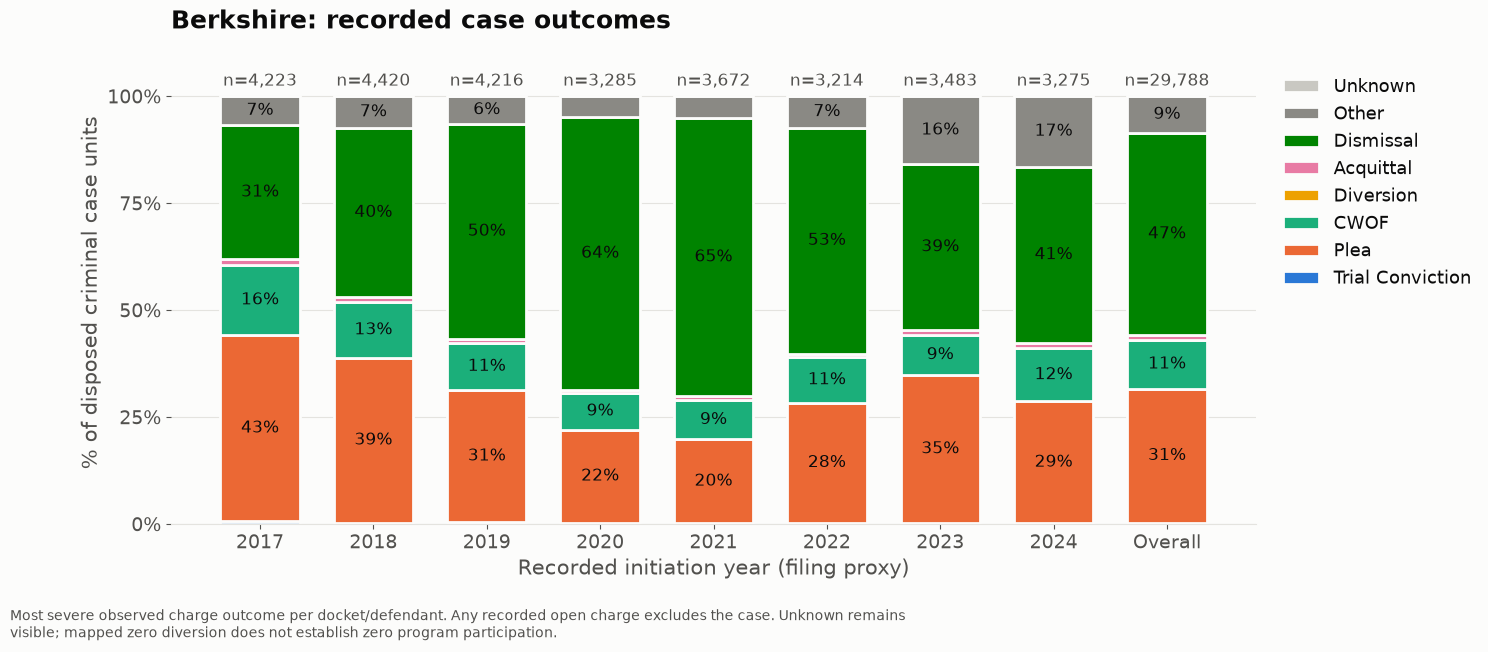

outcome,Trial Conviction,Plea,CWOF,Diversion,Acquittal,Dismissal,Other,Unknown
year,,,,,,,,
2017,26,1835,696,0,53,1327,286,0
2018,11,1705,573,0,53,1748,330,0
2019,13,1307,461,0,40,2122,273,0
2020,9,713,285,0,21,2097,160,0
2021,5,720,336,0,34,2389,188,0
2022,7,904,340,0,28,1698,237,0
2023,5,1208,325,0,43,1346,556,0
2024,3,935,405,0,42,1349,541,0
Overall,79,9327,3421,0,314,14076,2571,0


outcome,Trial Conviction,Plea,CWOF,Diversion,Acquittal,Dismissal,Other,Unknown
year,,,,,,,,
2017,0.615676,43.452522,16.481175,0.0,1.255032,31.423159,6.772437,0.0
2018,0.248869,38.574661,12.963801,0.0,1.199095,39.547511,7.466063,0.0
2019,0.308349,31.000949,10.934535,0.0,0.948767,50.332068,6.475332,0.0
2020,0.273973,21.704718,8.675799,0.0,0.639269,63.835616,4.870624,0.0
2021,0.136166,19.607843,9.150327,0.0,0.925926,65.059913,5.119826,0.0
2022,0.217797,28.126945,10.578718,0.0,0.871189,52.831363,7.373989,0.0
2023,0.143554,34.682745,9.331036,0.0,1.234568,38.644846,15.963250,0.0
2024,0.091603,28.549618,12.366412,0.0,1.282443,41.190840,16.519084,0.0
Overall,0.265207,31.311266,11.484490,0.0,1.054116,47.253928,8.630992,0.0


Overall denominator: 29,788 case units


In [7]:
outcome_ok=disposed_identity_ok and 'disposition' not in INSUFFICIENT
if outcome_ok:
    status('Q3','Partially answerable','Observed disposed-case shares are available. Filing semantics, unresolved cases and unverified diversion limit a complete answer.')
    counts,pct=charts.outcomes(cases,COUNTY,YEAR_LABEL,fig('q3_outcomes_by_year'))
    save_table('q3_outcome_counts',counts);save_table('q3_outcome_pct',pct)
    print('Overall denominator:',f'{len(cases):,}', 'case units')
else:
    status('Q3','Unavailable under shared rule','Disposition or case-identity missingness exceeds 20%.')
    charts.unavailable(COUNTY+': Q3',statuses[-1]['reason'],fig('q3_outcomes_by_year'))


## 4. Sentencing
    **Question:** What share of convictions result in incarceration, probation, or fines/other?
    **Method:** among case units with conviction evidence, select the most severe recorded sentence. CWOF is excluded.
    Berkshire uses translated sentence text and positive actual-jail amounts; a generic plea requires additional evidence.
    Cape uses imposed sentence codes; SS is suspended and F is filed, neither is automatically incarceration or probation.
    Blank evidence is Unknown, not zero. Missing-sentence share accompanies every released rate. If source or case-level missingness exceeds 20%, the rates are withheld.


Conviction-evidence case units: 6,008; case-level unknown sentence: 1.2%


**Unavailable under shared rule.** Sentence evidence exceeds 20% missing or fails an outcome/identity prerequisite. No incarceration/probation rate is released.

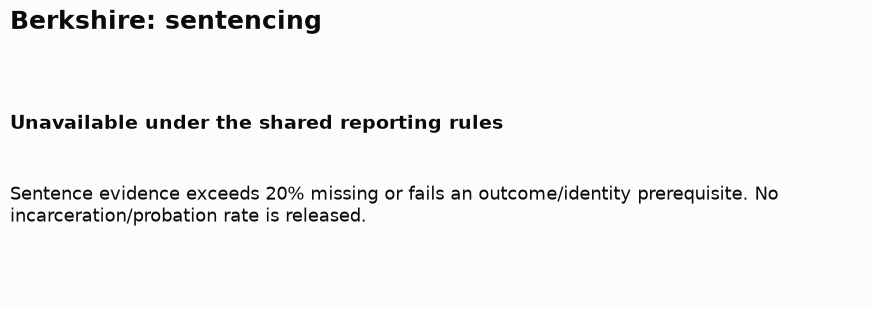

In [8]:
sentence_ok=outcome_ok and allowed('sentence')
convictions=cases[cases.conviction_evidence]
print(f'Conviction-evidence case units: {len(convictions):,}; case-level unknown sentence: {convictions.sentence.eq("Unknown").mean():.1%}')
if sentence_ok:
    status('Q4','Partially answerable','Recorded sentence types are available; markers do not establish time served, and pleas without conviction evidence are excluded.')
    save_table('q4_sentencing',charts.sentencing(cases,COUNTY,fig('q4_sentencing')))
else:
    status('Q4','Unavailable under shared rule','Sentence evidence exceeds 20% missing or fails an outcome/identity prerequisite. No incarceration/probation rate is released.')
    charts.unavailable(COUNTY+': sentencing',statuses[-1]['reason'],fig('q4_sentencing'))


## 5. Pretrial Detention and Bail
    **Question:** What share of defendants are held pretrial, and how often is cash bail set?
    **Method:** discard bail dates outside 2017–2024 before selecting the first recorded date. Retain conflicting same-day statuses as Unknown. Link only source case IDs that resolve to exactly one filed docket/defendant unit.
    This is a first recorded event, **not a verified arraignment**. Berkshire Cash/Surety does not establish cash-only bail; Cape BAIL does not specify mode. These remain Unknown in the shared cash-only metric. A recorded amount is not money collected. Posting, inability to post and detention duration are unavailable.


,first_event_case_ids,linked_filed_case_units,filed_case_units,coverage_pct,unknown_standard_status_pct,ambiguous_source_case_ids,note
0,17576,16465,32262,51.035274,17.017917,2,First recorded in-range event; arraignment and...


**Partially answerable.** First-event raw status composition is available. Arraignment, payment, posting and complete detention are not established.

,value
bail record coverage (% of filed cases),51.0
% PR,69.5
% explicitly cash-only bail (not all cash/surety),8.8
% held without bail,4.7
% no status (Unknown),17.0
% of cash-bail cases unable to post,NaN
median explicitly cash-only amount ($),250.0


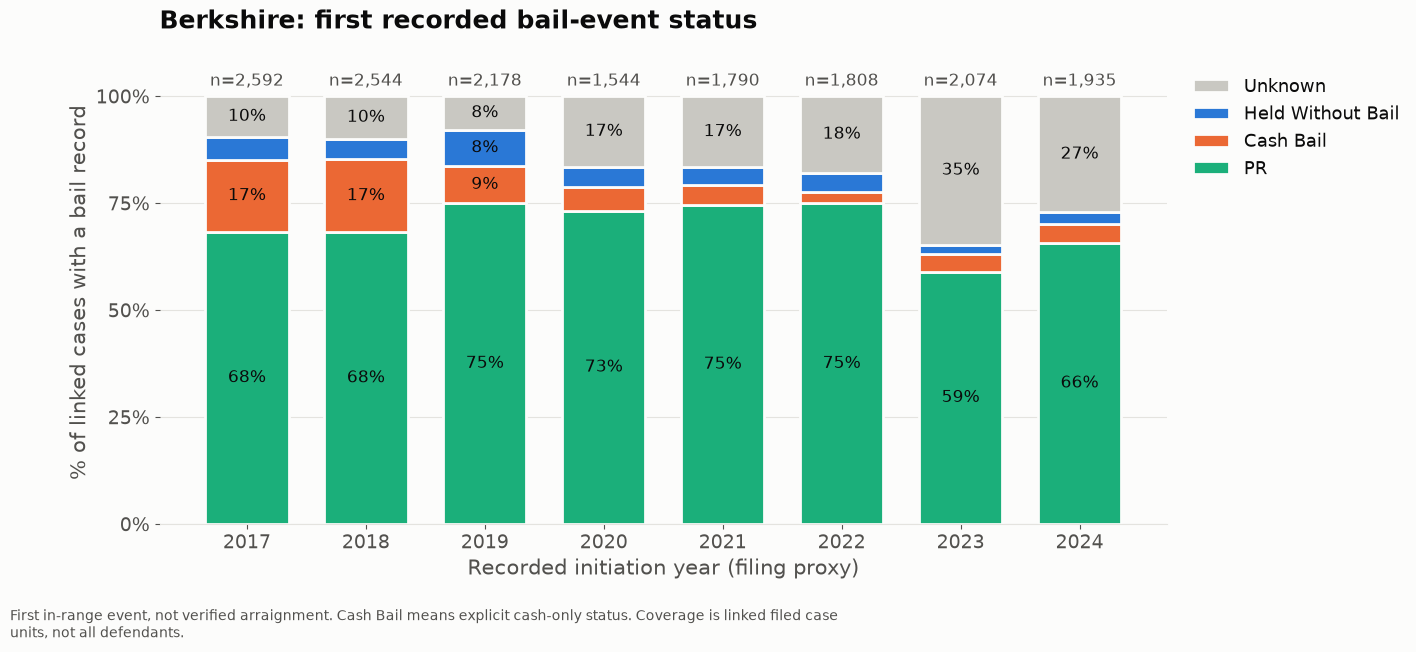

raw_status,Bail Revoked,Bound Over To Grand Jury,Cash Only,Cash/Surety,Conditions Only,Conflicting,Dangerousness Hearing held - released w/conditions,Detained on VOP,Electronic Monitoring,Held Pending Competency Hearing,Held Pending DH,Held Without Right To Bail,Held as a Danger,In Custody - Bail Set,No Bail,Other Facility,Out on Cash Bail,Personal Surety,Released on Own Recognizance
year,,,,,,,,,,,,,,,,,,,
2017,14,0,437,83,138,1,0,0,0,0,0,138,0,0,0,0,5,7,1769
2018,30,0,433,33,179,4,0,1,0,0,0,122,0,1,2,1,0,4,1734
2019,43,0,190,7,115,3,0,1,0,0,1,184,0,0,0,1,0,1,1632
2020,18,0,87,20,95,4,0,3,0,0,109,71,0,0,2,5,0,0,1130
2021,13,0,83,44,127,5,0,6,0,0,93,74,0,3,0,8,0,0,1334
2022,23,0,49,62,103,3,0,4,0,0,106,81,0,7,2,14,0,0,1354
2023,8,1,85,267,291,5,2,3,1,0,69,45,2,49,7,15,0,1,1223
2024,18,0,85,233,119,7,8,8,0,4,49,51,28,45,0,8,0,0,1272


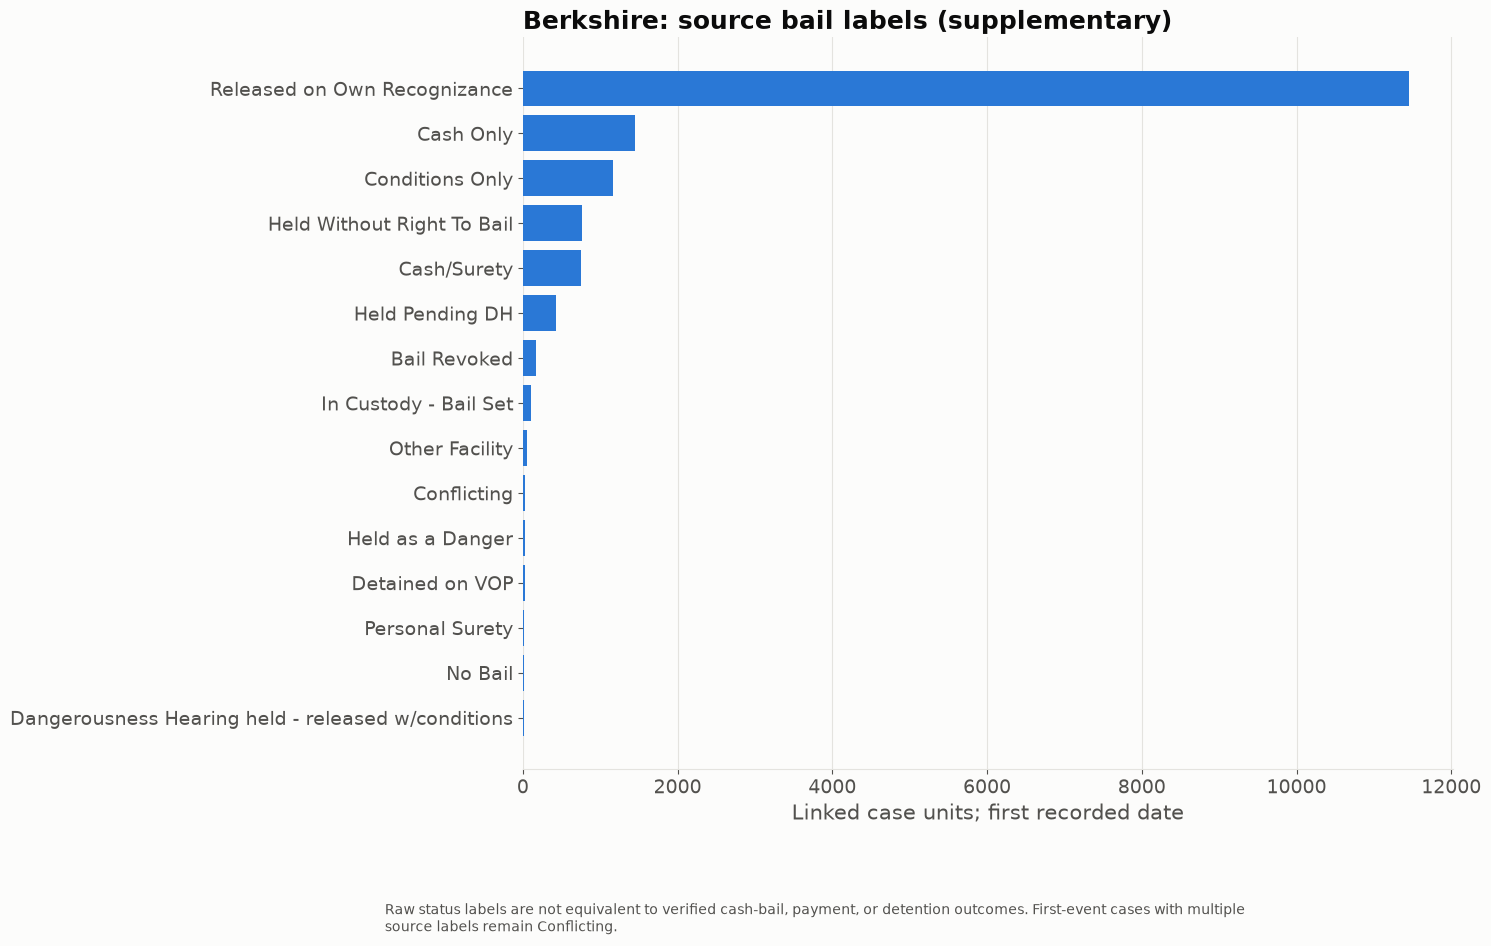

In [9]:
bail_std,bail_coverage=adapter.make_bail(bail,filed,filed_cases,SLUG)
save_table('q5_bail_coverage',bail_coverage)
status('Q5','Partially answerable','First-event raw status composition is available. Arraignment, payment, posting and complete detention are not established.')
unknown_share=bail_std.status.eq('Unknown').mean()
if filed_identity_ok and unknown_share<=.20 and len(bail_std):
    headline,by_year=bail_table(bail_std,n_filed=len(filed_cases))
    headline=headline.rename(index={'% cash bail set':'% explicitly cash-only bail (not all cash/surety)', 'median cash bail ($)':'median explicitly cash-only amount ($)'})
    save_table('q5_shared_metrics',headline)
    _,ax=plt.subplots(figsize=(13,6))
    stacked_pct_bar(by_year,colors=BAIL_COLORS,ax=ax,unit='linked cases with a bail record',xlabel=YEAR_LABEL,
        title=COUNTY+': first recorded bail-event status')
    charts.finish(ax.figure,fig('q5_bail_status'),'First in-range event, not verified arraignment. Cash Bail means explicit cash-only status. Coverage is linked filed case units, not all defendants.')
else:
    charts.unavailable(COUNTY+': shared bail metrics','More than 20% of standardized status is unknown/ambiguous, or identity coverage fails. Cash-only and held shares are withheld.',fig('q5_bail_status'))
    print('Shared PR/cash/held rates withheld; see the supplementary raw-status distribution below.')
raw_counts=pd.crosstab(bail_std.year,bail_std.raw_status)
raw_counts.index=raw_counts.index.astype(int)
save_table('q5_first_recorded_raw_status_counts',raw_counts)
# These are source-label counts, not a substitute cash-bail classification.
raw_total=raw_counts.sum().sort_values().tail(15)
_,ax=plt.subplots(figsize=(12,max(4,.5*len(raw_total)+2)))
ax.barh(raw_total.index,raw_total,color=OUTCOME_COLORS['Trial Conviction'])
ax.set(xlabel='Linked case units; first recorded date',title=COUNTY+': source bail labels (supplementary)')
ax.grid(axis='y',visible=False);ax.grid(axis='x')
charts.finish(ax.figure,fig('q5_raw_status_supplement'),'Raw status labels are not equivalent to verified cash-bail, payment, or detention outcomes. First-event cases with multiple source labels remain Conflicting.')


## 6. Time to Disposition
    **Question:** What is the median filing-to-disposition time, by offense category and court?
    **Method:** earliest initiation to latest recorded disposition in Berkshire. Pending cases, negative intervals, and cases with missing disposition endpoints are excluded from duration calculations.
    Cape has no filing date: a separately labeled offense-to-disposition interval is supplementary and does not answer the requested interval. Substantive offense categories are unavailable; source class is supplementary. Groups below 30 usable intervals are omitted.


,case_units,missing_or_incomplete_endpoints,negative_intervals,usable_intervals
0,29788,0,2759,27029


**Partially answerable.** Initiation approximates filing; substantive offense-category mapping is absent.

Initiation to disposition: median 97 days; IQR 35–238; n=27,029


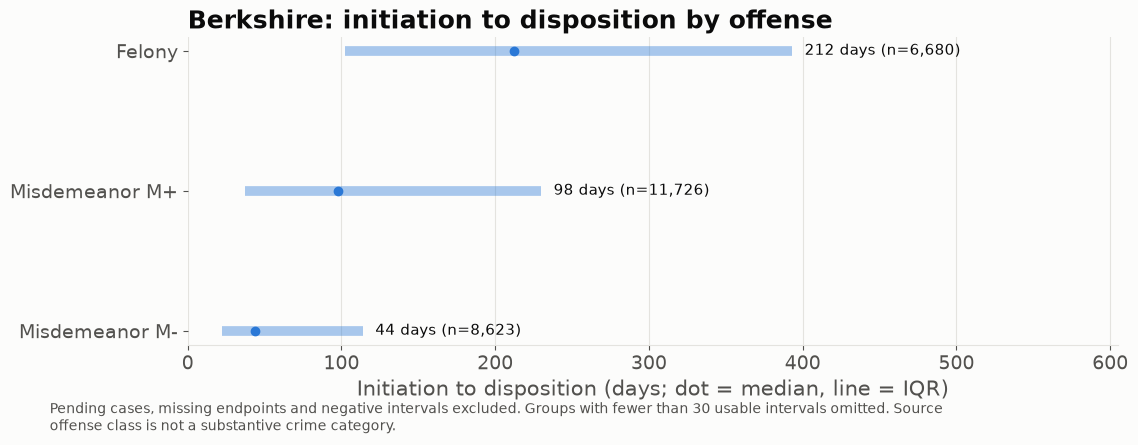

,n,median,q1,q3
offense,,,,
Felony,6680,212.0,102.0,393.25
Misdemeanor M+,11726,98.0,37.0,230.00
Misdemeanor M-,8623,44.0,22.0,114.00


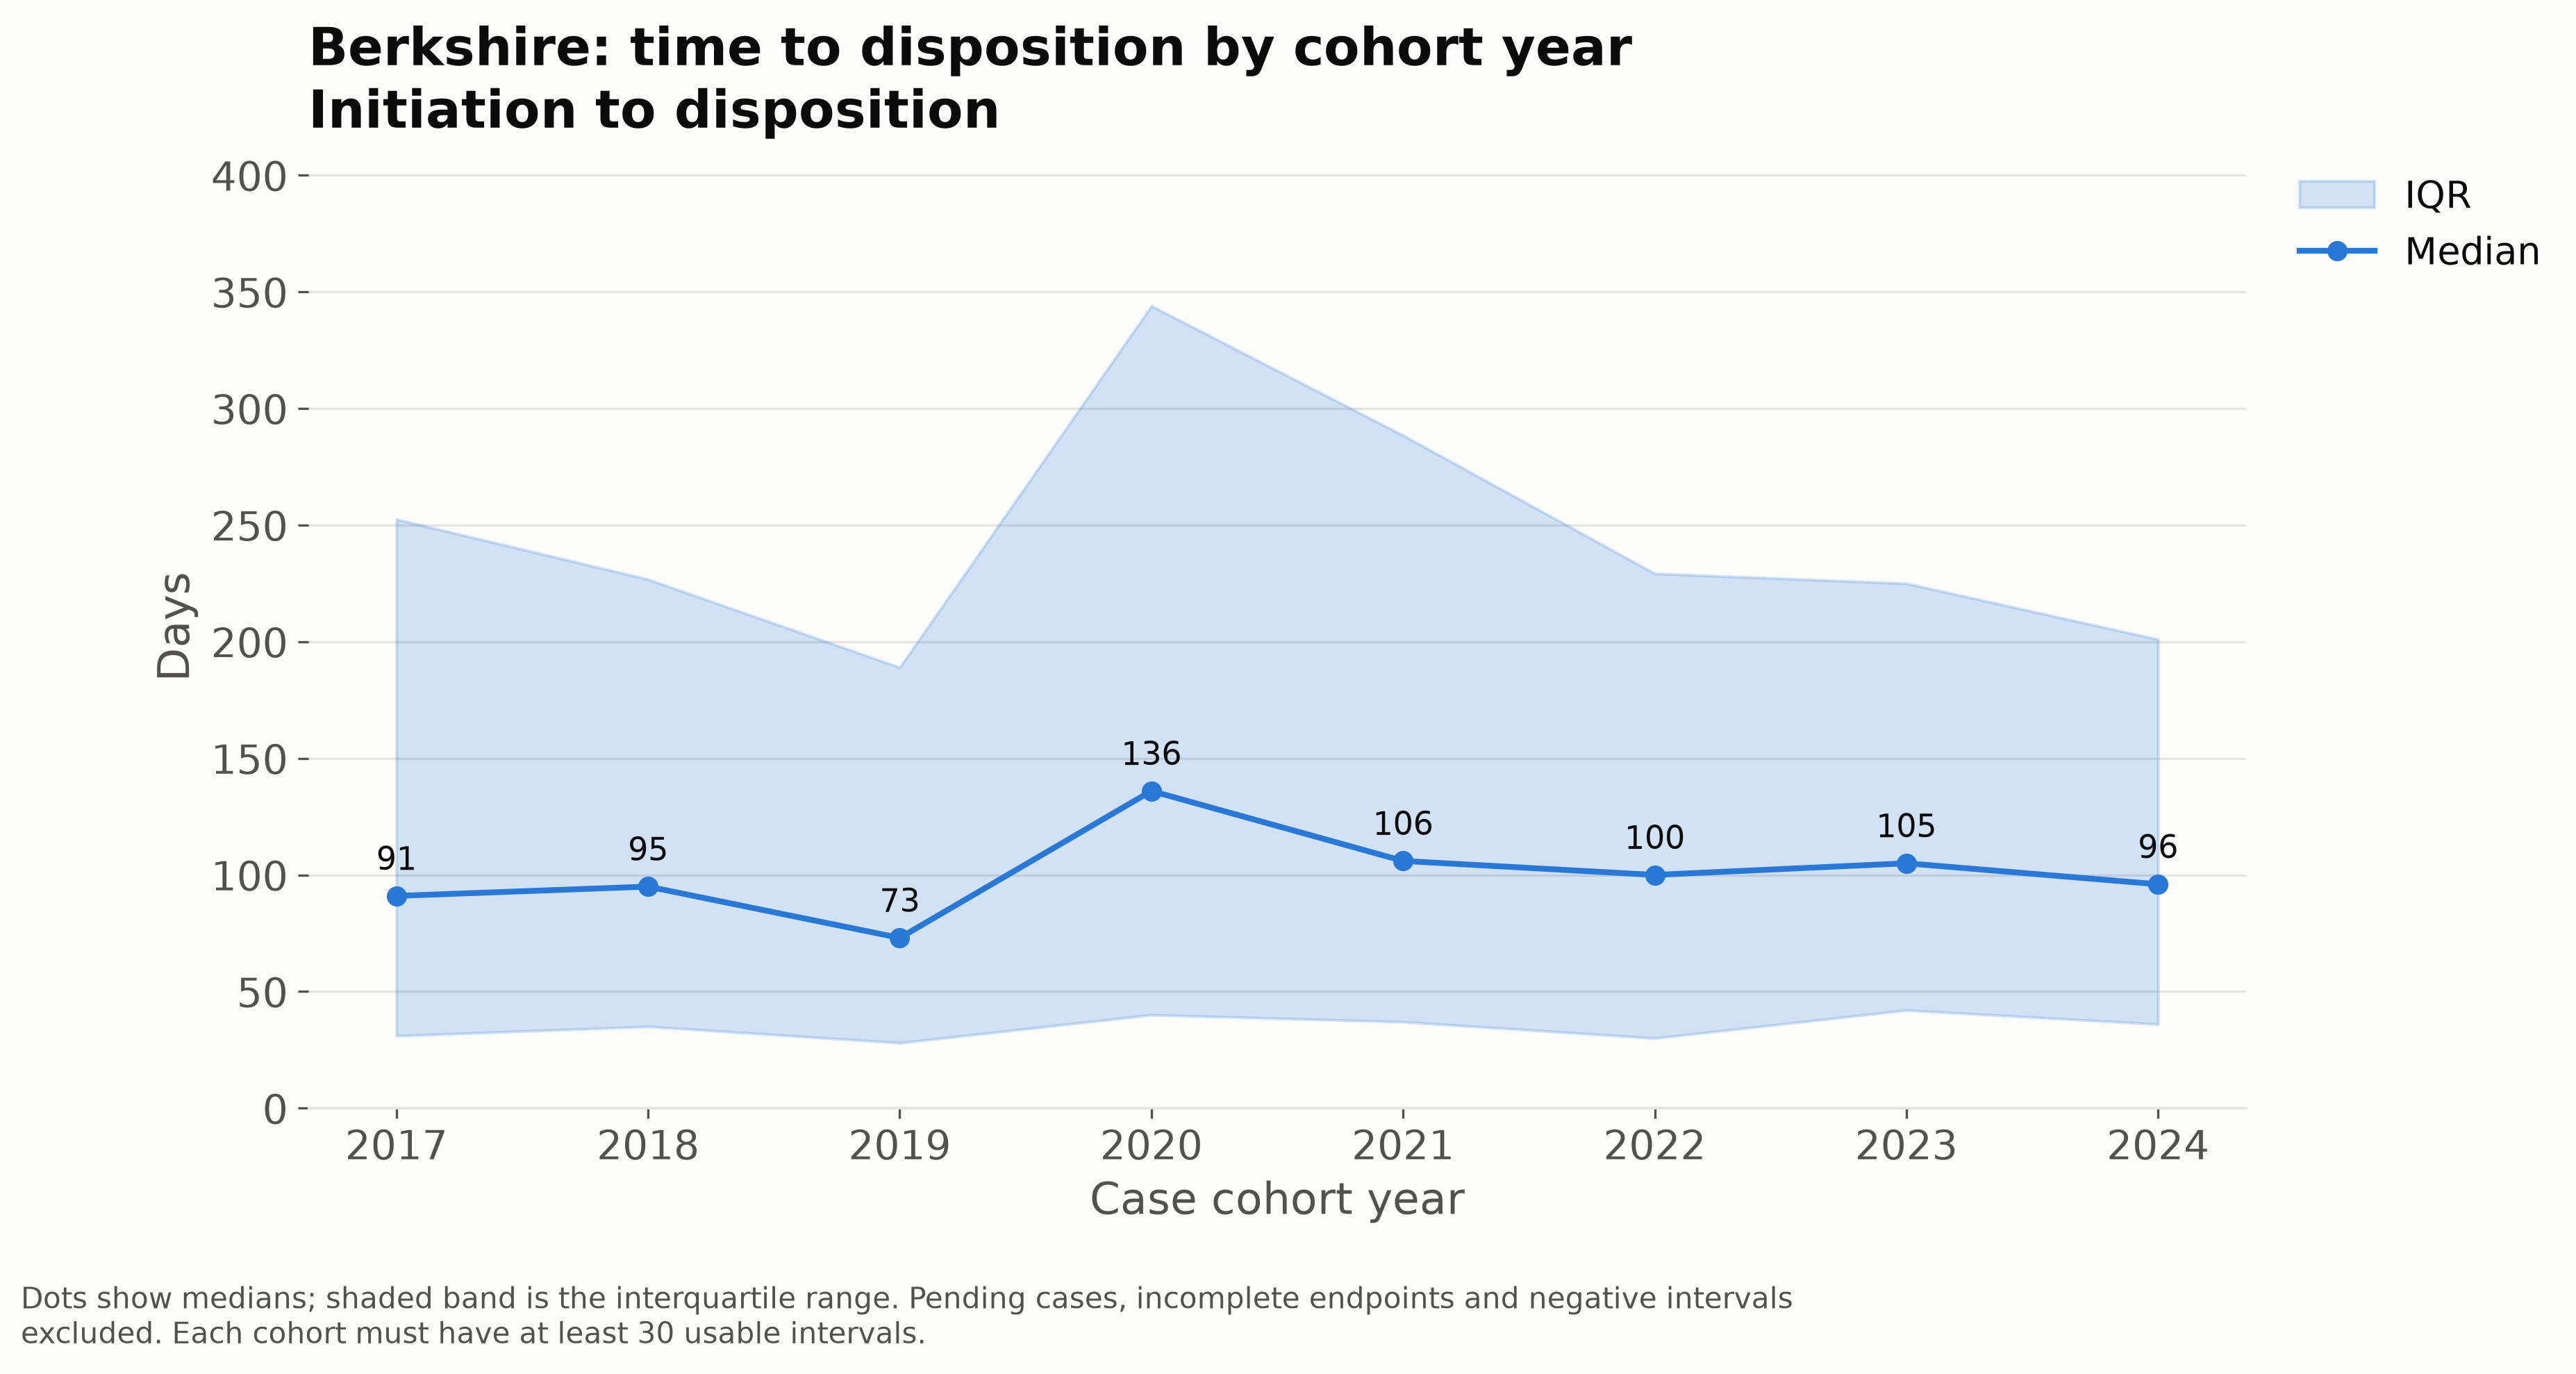

,n,median,q1,q3
year,,,,
2017,3935,91.0,31.0,252.50
2018,4174,95.0,35.0,226.75
2019,3911,73.0,28.0,189.00
2020,2976,136.0,40.0,344.00
2021,2900,106.0,37.0,288.50
2022,2760,100.0,30.0,229.25
2023,3239,105.0,42.0,225.00
2024,3134,96.0,36.0,201.00


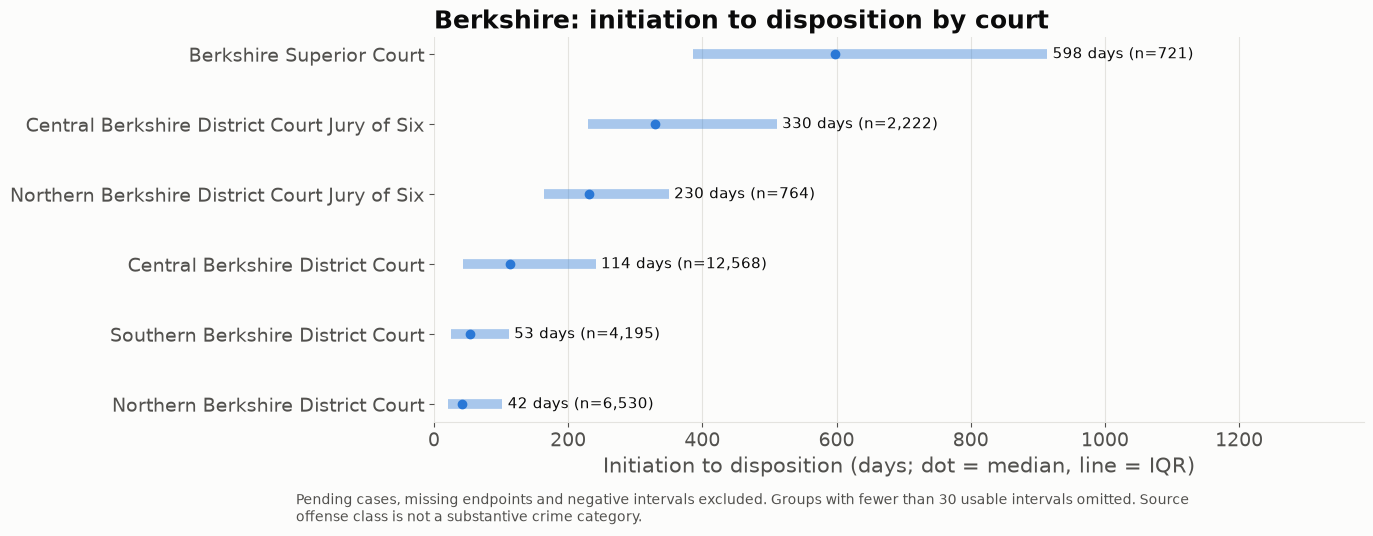

,n,median,q1,q3
court,,,,
Berkshire Superior Court,721,598.0,386.00,914.00
Central Berkshire District Court,12568,114.0,44.00,241.00
Central Berkshire District Court Jury of Six,2222,329.5,229.25,510.75
Northern Berkshire District Court,6530,42.0,21.00,102.00
Northern Berkshire District Court Jury of Six,764,230.5,164.00,350.00
Southern Berkshire District Court,4195,53.0,26.00,111.50


In [10]:
interval='days' if BERK else 'offense_days'
duration=cases.copy()
duration.loc[duration.any_missing_disposition_date,interval]=np.nan
audit=pd.DataFrame([dict(case_units=len(cases),missing_or_incomplete_endpoints=int(duration[interval].isna().sum()),
    negative_intervals=int(duration[interval].lt(0).sum()),usable_intervals=int(duration[interval].ge(0).sum()))])
save_table('q6_date_interval_audit',audit)
status('Q6','Partially answerable' if BERK else 'Requested interval unavailable; supplementary interval shown',
    'Initiation approximates filing; substantive offense-category mapping is absent.' if BERK else 'No filing date exists. Offense-to-disposition cannot be relabeled filing-to-disposition.')
label='Initiation to disposition' if BERK else 'Offense to disposition (supplementary)'
endpoints_ok='disposition_date' not in INSUFFICIENT
if endpoints_ok:
    usable=duration.loc[duration[interval].ge(0),interval]
    print(f'{label}: median {usable.median():.0f} days; IQR {usable.quantile(.25):.0f}–{usable.quantile(.75):.0f}; n={len(usable):,}')
    save_table('q6_time_by_source_class',charts.time_chart(duration,'offense',COUNTY,fig('q6_time_by_offense'),interval,label))
    save_table('q6_time_by_cohort',charts.time_chart(duration,'year',COUNTY,fig('q6_time_by_year'),interval,label))
    if allowed('court'):
        save_table('q6_time_by_court',charts.time_chart(duration,'court',COUNTY,fig('q6_time_by_court'),interval,label))
    else:
        charts.unavailable(COUNTY+': time by court','Court coverage exceeds 20% missing/conflicting; court-specific duration is withheld.',fig('q6_time_by_court'))
else:
    charts.unavailable(COUNTY+': time to disposition','Disposition-date coverage exceeds 20% missing.',fig('q6_time_by_offense'))


## 7. Disparities by Race and Sex
    **Question:** Do dismissal and incarceration rates differ by race/ethnicity and sex?
    **Denominators:** all eligible disposed case units for dismissal; conviction-evidence case units for incarceration.
    Compare with White for race and Male for sex. Keep Missing and explicit Unknown separate. Suppress groups below 30 and withhold a metric when the relevant field exceeds 20% missing.
    These are descriptive recorded differences, not evidence of unequal treatment after controlling for case mix. Declinations before filing cannot be measured.


,n,events,missing_sentence,rate_pct,suppressed,ratio_vs_White,missing_sentence_pct,metric,group
0,84,45.0,78.0,53.571429,False,1.192142,NaN,dismissal,Asian
1,4817,2467.0,3762.0,51.214449,False,1.139692,NaN,dismissal,Black
2,41,16.0,38.0,39.024390,False,0.868422,NaN,dismissal,Code BR (unverified)
3,3,NaN,NaN,NaN,True,NaN,NaN,dismissal,Code EI (unverified)
4,4,NaN,NaN,NaN,True,NaN,NaN,dismissal,Code I (unverified)
5,50,20.0,39.0,40.000000,False,0.890133,NaN,dismissal,Code M (unverified)
6,3,NaN,NaN,NaN,True,NaN,NaN,dismissal,Code MNA (unverified)
7,1173,693.0,1012.0,59.079284,False,1.314710,NaN,dismissal,Hispanic (source race field)
8,635,378.0,589.0,59.527559,False,1.324686,NaN,dismissal,Missing
9,718,448.0,674.0,62.395543,False,1.388508,NaN,dismissal,Unknown (U)


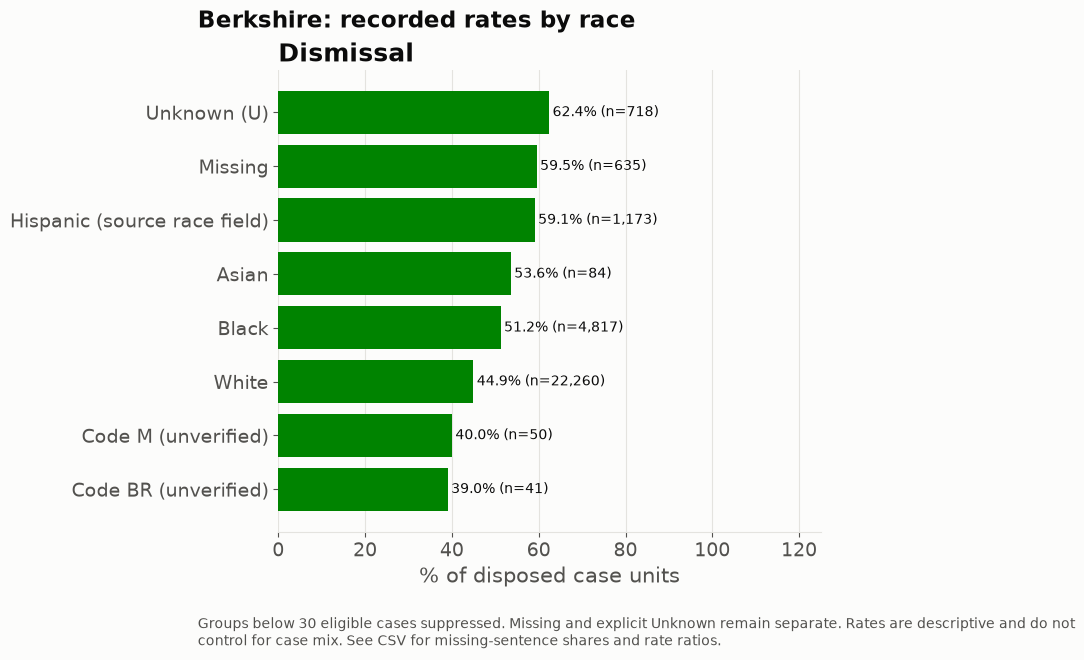

,n,events,missing_sentence,rate_pct,suppressed,ratio_vs_Male,missing_sentence_pct,metric,group
0,7,NaN,NaN,NaN,True,NaN,NaN,dismissal,Code N (unverified)
1,8747,4564.0,7620.0,52.177890,False,1.157072,NaN,dismissal,Female
2,20947,9446.0,16141.0,45.094763,False,1.000000,NaN,dismissal,Male
3,69,51.0,67.0,73.913043,False,1.639060,NaN,dismissal,Missing
4,18,NaN,NaN,NaN,True,NaN,NaN,dismissal,Unknown (U)


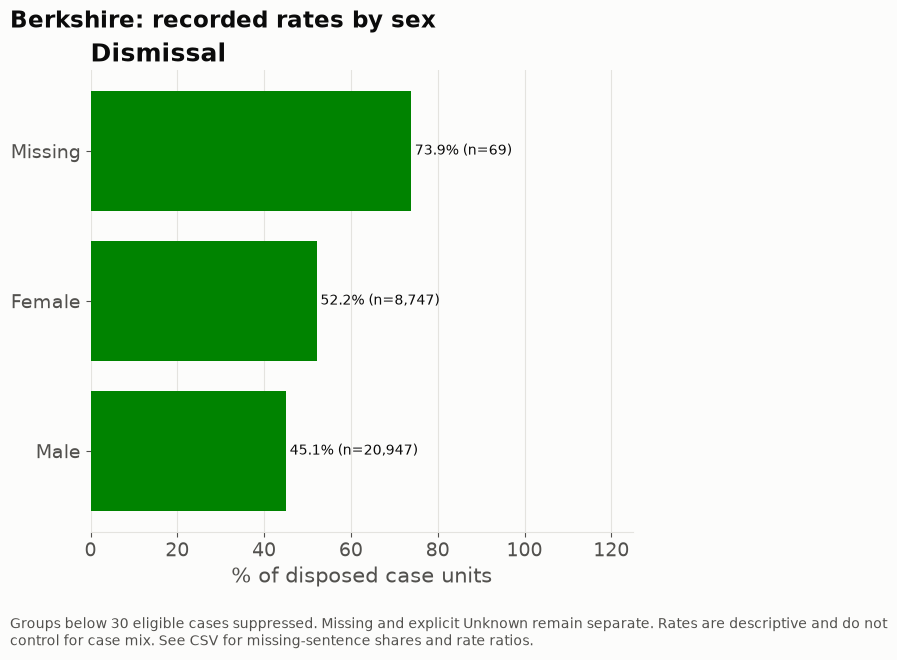

**Partially answerable.** Released: race dismissal only, sex dismissal only. Missingness and suppression remain material limitations.

In [11]:
released=[]
for group in ['race','sex']:
    if outcome_ok and allowed(group):
        rates=charts.disparity_table(cases,group)
        if not sentence_ok:
            rates=rates[rates.metric.eq('dismissal')].copy()
        save_table('q7_'+group,rates)
        charts.disparities(rates,COUNTY,group,fig('q7_rates_by_'+group),sentence_ok)
        released.append(group+' dismissal'+(' and incarceration' if sentence_ok else ' only'))
    else:
        charts.unavailable(COUNTY+': disparities by '+group,'The relevant coverage or outcome prerequisite fails the shared rule; rates are withheld.',fig('q7_rates_by_'+group))
status('Q7','Partially answerable' if released else 'Unavailable under shared rule',
    'Released: '+', '.join(released)+'. Missingness and suppression remain material limitations.' if released else 'Relevant demographic/outcome coverage exceeds the threshold.')


## 8. Disparities with Controls
    **Question:** Do racial gaps remain within the same offense category and prior-record level?
    **Unavailable as specified.** Neither county supplies a validated prior-record field or complete common three-year filing history. Cape also lacks filing dates.
    An extract-observed earlier case is not necessarily a prior conviction or statewide criminal history. We do not assign zero priors from missing history.
    The supplementary graph compares dismissal within the same representative charge code/description, **without prior-record adjustment**. Both race cells must contain at least 30 eligible cases. It does not establish that gaps remain after the requested controls.


**Full answer unavailable; limited supplementary comparison.** Validated prior-record history and a shared substantive offense crosswalk are missing. No controlled racial-gap estimate is reported.

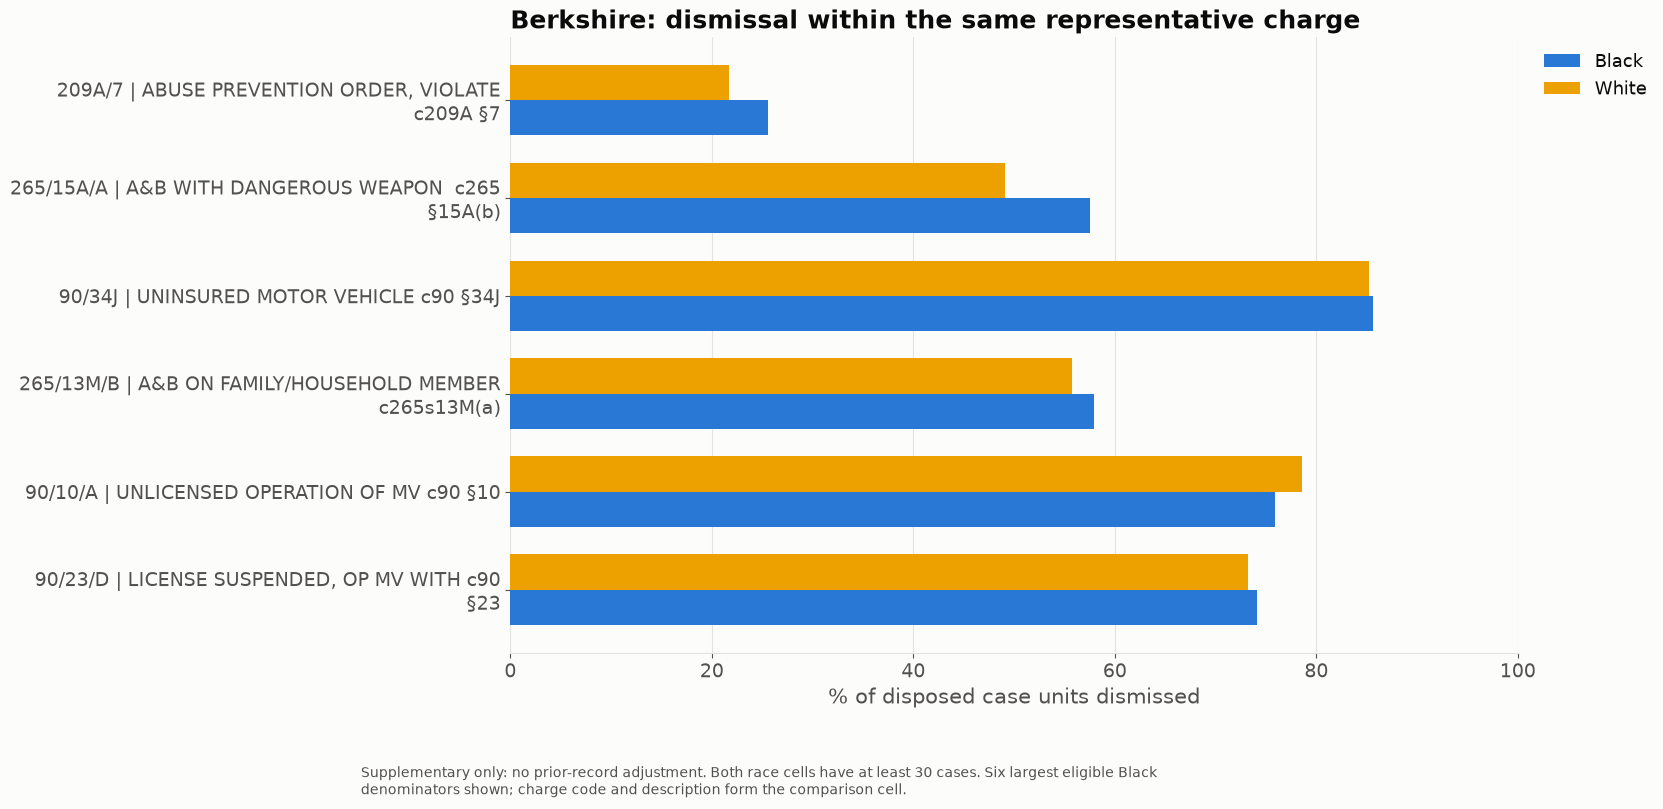

n  events  \
charge                                             race                       
209A/7 | ABUSE PREVENTION ORDER, VIOLATE c209A §7  Black        180      46   
                                                   White        690     150   
22E/11 | DNA DATABASE SAMPLE, REFUSE PROVIDE c2... White         48      46   
234A/42 | JUROR FAIL TO ATTEND c234A §42           Missing       49      49   
                                                   Unknown (U)   76      76   
...                                                             ...     ...   
94C/34/C | DRUG, POSSESS CLASS B c94C §34          Black         35      11   
                                                   White        267      95   
94C/34/D | DRUG, POSSESS CLASS B, SUBSQ.OFF. c9... White         52      21   
94C/34/J | HEROIN, POSSESS c94C §34                White         34       9   
94C/40 | CONSPIRACY TO VIOLATE DRUG LAW  c94C §40  White         39      16   

                                                                  rate_pct  \
charge                                             race                      
209A/7 | ABUSE PREVENTION ORDER, VIOLATE c209A §7  Black         25.555556   
                                                   White         21.739130   
22E/11 | DNA DATABASE SAMPLE, REFUSE PROVIDE c2... White         95.833333   
234A/42 | JUROR FAIL TO ATTEND c234A §42           Missing      100.000000   
                                                   Unknown (U)  100.000000   
...                                                                    ...   
94C/34/C | DRUG, POSSESS CLASS B c94C §34          Black         31.428571   
                                                   White         35.580524   
94C/34/D | DRUG, POSSESS CLASS B, SUBSQ.OFF. c9... White         40.384615   
94C/34/J | HEROIN, POSSESS c94C §34                White         26.470588   
94C/40 | CONSPIRACY TO VIOLATE DRUG LAW  c94C §40  White         41.025641   

                                                                 white_pct  \
charge                                             race                      
209A/7 | ABUSE PREVENTION ORDER, VIOLATE c209A §7  Black         21.739130   
                                                   White         21.739130   
22E/11 | DNA DATABASE SAMPLE, REFUSE PROVIDE c2... White         95.833333   
234A/42 | JUROR FAIL TO ATTEND c234A §42           Missing      100.000000   
                                                   Unknown (U)  100.000000   
...                                                                    ...   
94C/34/C | DRUG, POSSESS CLASS B c94C §34          Black         35.580524   
                                                   White         35.580524   
94C/34/D | DRUG, POSSESS CLASS B, SUBSQ.OFF. c9... White         40.384615   
94C/34/J | HEROIN, POSSESS c94C §34                White         26.470588   
94C/40 | CONSPIRACY TO VIOLATE DRUG LAW  c94C §40  White         41.025641   

                                                                ratio_vs_white  
charge                                             race                         
209A/7 | ABUSE PREVENTION ORDER, VIOLATE c209A §7  Black              1.175556  
                                                   White              1.000000  
22E/11 | DNA DATABASE SAMPLE, REFUSE PROVIDE c2... White              1.000000  
234A/42 | JUROR FAIL TO ATTEND c234A §42           Missing            1.000000  
                                                   Unknown (U)        1.000000  
...                                                                        ...  
94C/34/C | DRUG, POSSESS CLASS B c94C §34          Black              0.883308  
                                                   White              1.000000  
94C/34/D | DRUG, POSSESS CLASS B, SUBSQ.OFF. c9... White              1.000000  
94C/34/J | HEROIN, POSSESS c94C §34                White              1.000000  
94C/40 | CONSPIRACY TO VIOLATE DRUG 

In [12]:
status('Q8','Full answer unavailable; limited supplementary comparison',
    'Validated prior-record history and a shared substantive offense crosswalk are missing. No controlled racial-gap estimate is reported.')
if outcome_ok and allowed('race'):
    save_table('q8_offense_only_dismissal',charts.offense_only(cases,COUNTY,fig('q8_offense_only_dismissal_supplement')))
else:
    charts.unavailable(COUNTY+': Q8 supplementary comparison','Race or outcome coverage fails the shared threshold.',fig('q8_offense_only_dismissal_supplement'))


## Questions for the Client and Remaining Blockers
    1. Does Berkshire Initiated Dt represent court filing? What does Cape's case-ID year mean, and can actual filing dates be provided?
    2. How should district/superior docket pairs, transfers, multiple defendants, and court-stage charge histories be linked?
    3. Can the team approve a substantive offense-category crosswalk and explain placeholders/unmapped charge codes?
    4. What evidence distinguishes a recorded plea, guilty finding, CWOF, suspended sentence, and actual custody? Can missing sentence types be supplied?
    5. Do bail events identify arraignment, cash versus surety, posting, and detention periods? What do same-day conflicting statuses mean?
    6. Is a consistent three-year history available before each cohort, and is the intended control earlier cases or prior convictions?
    7. Can demographic gaps and the extract's open/closed-case coverage be clarified?
    8. Should the 20% sentence-missingness rule apply to all disposed charges, or only conviction-eligible records? The supplied template uses all disposed charges, including records where sentencing may not apply; this revision follows that stricter source-field rule.

    Original spreadsheets and the supplied ZIP remain unchanged. Review the exported coverage, exclusions, crosswalk and audit tables before comparing counties.


In [13]:
save_table('question_answerability',pd.DataFrame(statuses).set_index('question'))
assert len(statuses)==8 and len(set(x['question'] for x in statuses))==8
assert cases.index.is_unique and filed_cases.index.is_unique
assert not cases.outcome.eq('Pending').any()
assert int(vol.sum())==len(filed_cases)
if 'q3_outcome_counts' in tables:
    assert int(tables['q3_outcome_counts'].loc['Overall'].sum())==len(cases)
assert all(not name.startswith('raw_') for name in tables)
validation=dict(county=SLUG,checks='passed',filed_units=len(filed_cases),disposed_units=len(cases),
    tables=len(tables),figures=len(list(FIG_DIR.glob('*.png'))),source_sha256=source_hashes)
(COUNTY_DIR/'validation_summary.json').write_text(json.dumps(validation,indent=2),encoding='utf8')
print('Validation passed. Aggregate tables and 300 dpi figures saved. Source records were not exported.')


,status,reason
question,,
Q1,Partially answerable,Recorded initiation is a filing proxy.
Q2,Partially answerable,The numerator inherits Q1’s initiation/ID-year...
Q3,Partially answerable,Observed disposed-case shares are available. F...
Q4,Unavailable under shared rule,Sentence evidence exceeds 20% missing or fails...
Q5,Partially answerable,First-event raw status composition is availabl...
Q6,Partially answerable,Initiation approximates filing; substantive of...
Q7,Partially answerable,"Released: race dismissal only, sex dismissal o..."
Q8,Full answer unavailable; limited supplementary...,Validated prior-record history and a shared su...


Validation passed. Aggregate tables and 300 dpi figures saved. Source records were not exported.
